<a href="https://colab.research.google.com/github/JasmineNasywa/PCVK_Ganjil_2026/blob/main/week7_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
NAMA = 'Jasmine Nasywa N'
NIM = '244107020119'

print(NAMA, NIM)

Jasmine Nasywa N 244107020119


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

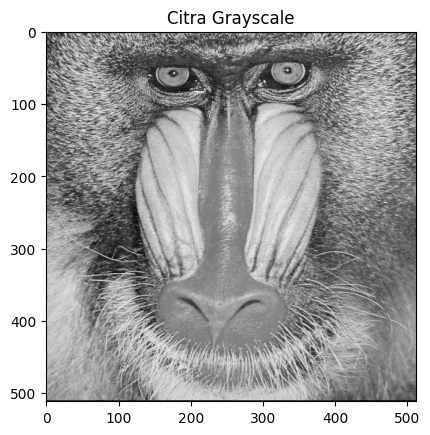

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/mandrill.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.imshow(img_gray, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('on')
plt.show()

In [ ]:
def convolution2d(image, kernel, stride=1, padding=0):
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape

    if padding > 0:
        image_padded = np.pad(image, padding, mode='constant', constant_values=0)
    else:
        image_padded = image

    pad_h, pad_w = image_padded.shape

    out_h = int((pad_h - k_h) / stride) + 1
    out_w = int((pad_w - k_w) / stride) + 1

    output = np.zeros((out_h, out_w))

    for y in range(0, out_h):
        for x in range(0, out_w):
            region = image_padded[y * stride:y * stride + k_h, x * stride:x * stride + k_w]
            output[y, x] = np.sum(region * kernel)

    return output

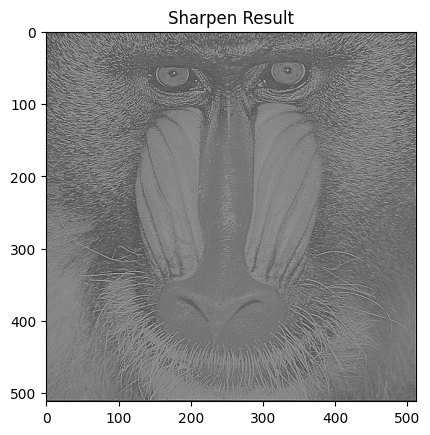

In [ ]:
#coba sharpen :)
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

result_sharpen = convolution2d(img_gray, kernel_sharpen, stride=1, padding=1)


plt.imshow(result_sharpen, cmap='gray')
plt.title('Sharpen Result')
plt.axis('on')
plt.show()

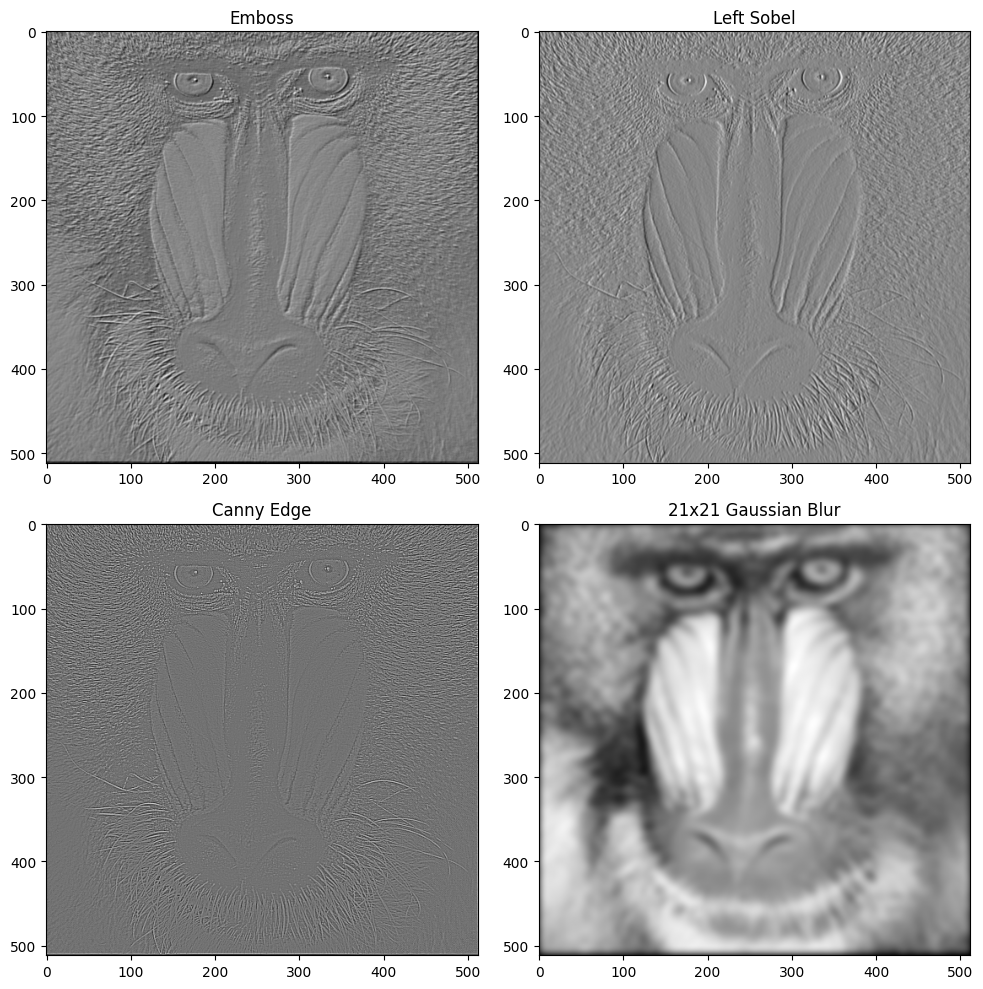

In [ ]:
# 1. Emboss Filter
kernel_emboss = np.array([[-2, -1,  0],
                          [-1,  1,  1],
                          [ 0,  1,  2]])
result_emboss = convolution2d(img_gray, kernel_emboss, stride=1, padding=1)

# 2. Left Sobel Edge Detection
kernel_sobel = np.array([[ 1,  0, -1],
                         [ 2,  0, -2],
                         [ 1,  0, -1]])
result_sobel = convolution2d(img_gray, kernel_sobel, stride=1, padding=1)

# 3. Canny/High-pass Filter (Laplacian-like)
kernel_canny = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])
result_canny = convolution2d(img_gray, kernel_canny, stride=1, padding=1)

# 4. 21x21 Gaussian Blur
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()
result_gaussian = convolution2d(img_gray, gauss_kernel, stride=1, padding=kernel_size//2)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(result_emboss, cmap='gray'); axes[0, 0].set_title('Emboss')
axes[0, 1].imshow(result_sobel, cmap='gray'); axes[0, 1].set_title('Left Sobel')
axes[1, 0].imshow(result_canny, cmap='gray'); axes[1, 0].set_title('Canny Edge')
axes[1, 1].imshow(result_gaussian, cmap='gray'); axes[1, 1].set_title('21x21 Gaussian Blur')

for ax in axes.flat:
    ax.axis('on')
plt.tight_layout()
plt.show()

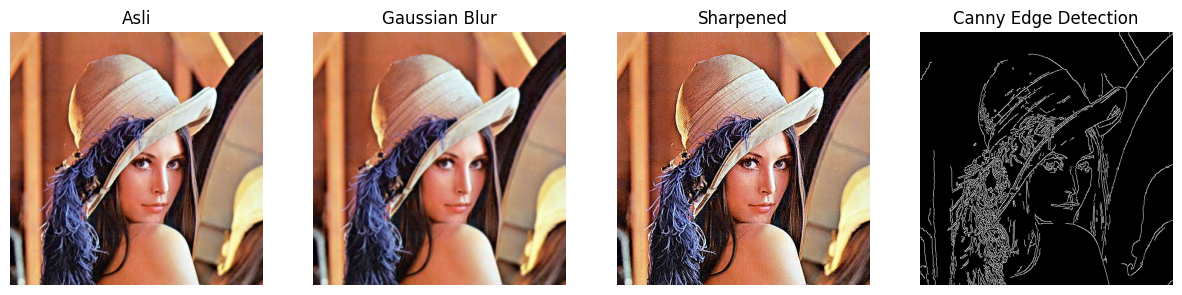

In [ ]:

def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread("/content/drive/MyDrive/PCVK/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)


blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)

show_side_by_side(
    [img, blur, sharpened, edges],
    ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"]
)

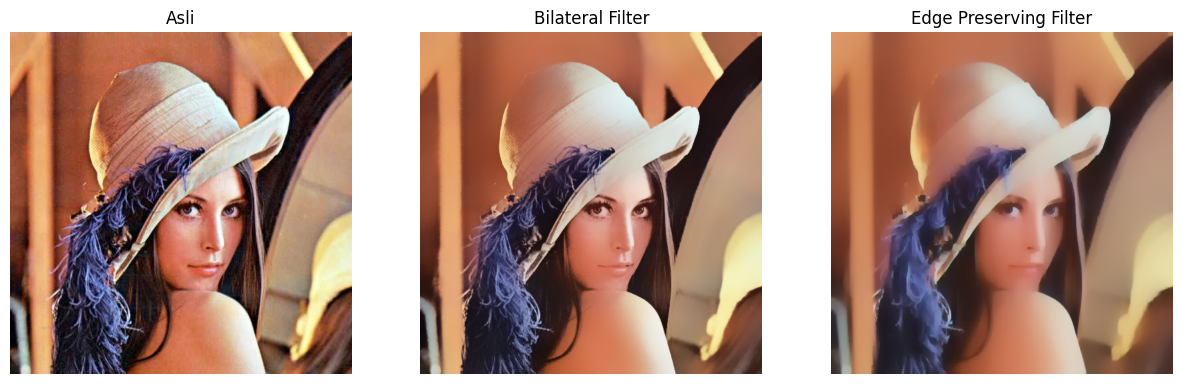

In [ ]:
bilateral = cv.bilateralFilter(img, 50, 100, 100)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side(
    [img, bilateral, edge_preserve],
    ["Asli", "Bilateral Filter", "Edge Preserving Filter"]
)

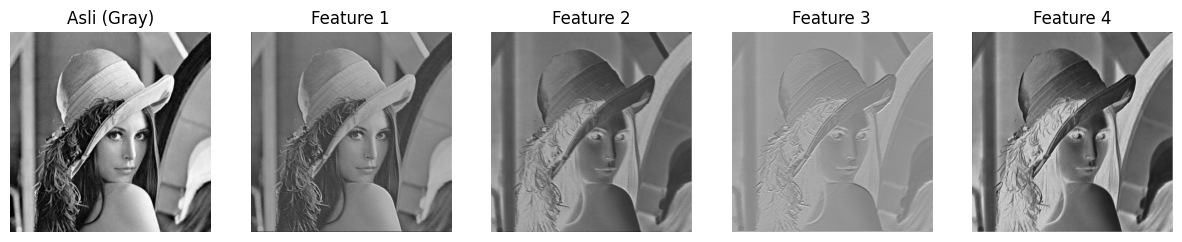

In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

with torch.no_grad():
    features = model(img_tensor)

feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]

show_side_by_side(
    [img_gray] + feature_maps,
    ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))]
)

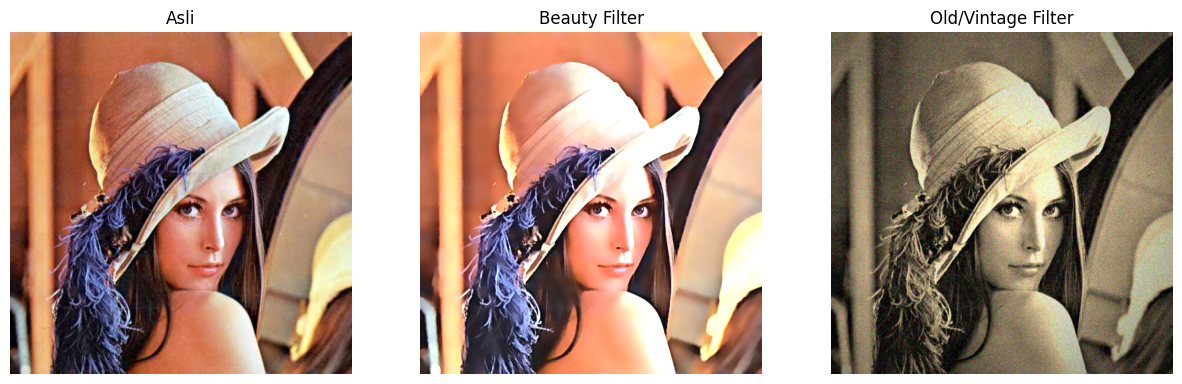

In [ ]:
# ===============================
# 1. Beauty Filter
# ===============================
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (mempertajam area mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # kontras
beta = 15    # kecerahan
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# ===============================
# 2. Old/Vintage Filter
# ===============================
# Step 1: Sepia tone menggunakan matriks transformasi warna
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette (efek pinggiran foto menggelap)
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain (menambahkan bintik-bintik ala film analog)
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side(
    [img, beauty, old_img],
    ["Asli", "Beauty Filter", "Old/Vintage Filter"]
)

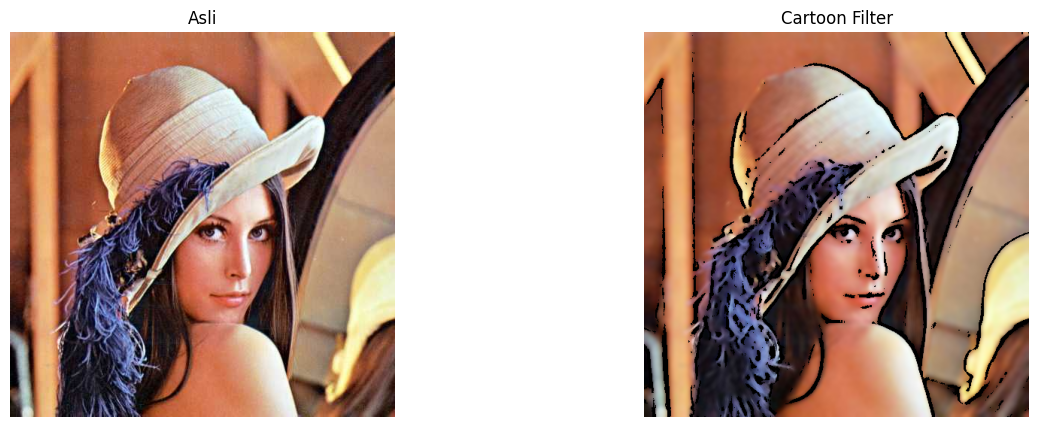

In [ ]:
# Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                              cv.ADAPTIVE_THRESH_MEAN_C,
                              cv.THRESH_BINARY, 9, 9)
# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

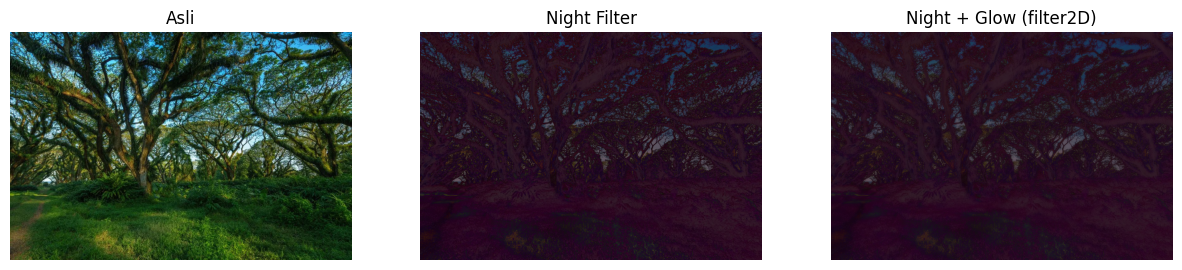

In [21]:
# Percobaan 6: Night Filter

img_night = cv.imread("/content/drive/MyDrive/PCVK/djawatan.jpg")


# Step 1: Gelapkan (kontras turun, brightness negatif)
night = cv.convertScaleAbs(img_night, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # Format BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel_night = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel_night)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

# Tampilkan hasil Percobaan 6
show_side_by_side(
    [img_night, night, night_glow],
    ["Asli", "Night Filter", "Night + Glow (filter2D)"]
)

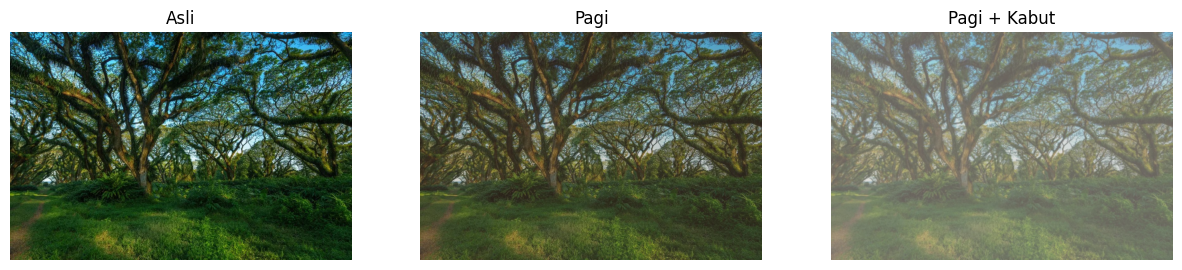

In [24]:
# Percobaan 7: Suasana Pagi dan Kabut
# Step 1: Kurangi kontras & cerahkan
alpha = 0.9  # contrast
beta = 20    # brightness
soft = cv.convertScaleAbs(img_night, alpha=alpha, beta=beta)

# Step 2: Tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120))  # Format BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel_g = cv.getGaussianKernel(3, 3)
kernel_fog = kernel_g @ kernel_g.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel_fog)

# Tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

# Tampilkan hasil Percobaan 7
show_side_by_side(
    [img_night, pagi, kabut],
    ["Asli", "Pagi", "Pagi + Kabut"]
)

#Tugas Praktikum



###1. Tugas Analisis: Perbandingan Mean Filter vs. Median Filter pada Noise Salt and Pepper

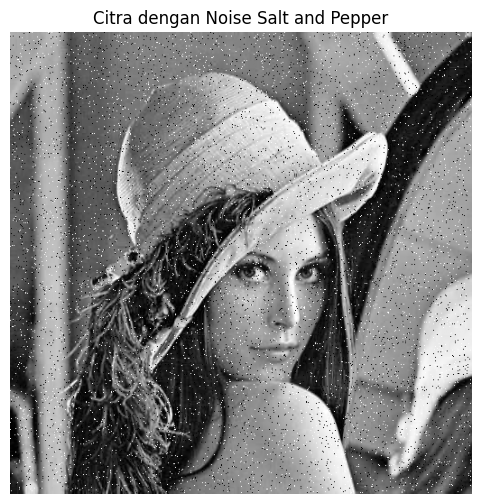

In [27]:
def add_salt_and_pepper_noise(image, salt_prob, pepper_prob):
    noisy_image = image.copy()

    # Salt (titik putih)
    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy_image[tuple(coords)] = 255

    # Pepper (titik hitam)
    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy_image[tuple(coords)] = 0

    return noisy_image

# Ubah citra ke grayscale lalu tambahkan noise
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_noisy = add_salt_and_pepper_noise(img_gray, 0.02, 0.02)

# Tampilkan citra ber-noise
plt.figure(figsize=(6, 6))
plt.imshow(img_noisy, cmap='gray')
plt.title("Citra dengan Noise Salt and Pepper")
plt.axis("off")
plt.show()

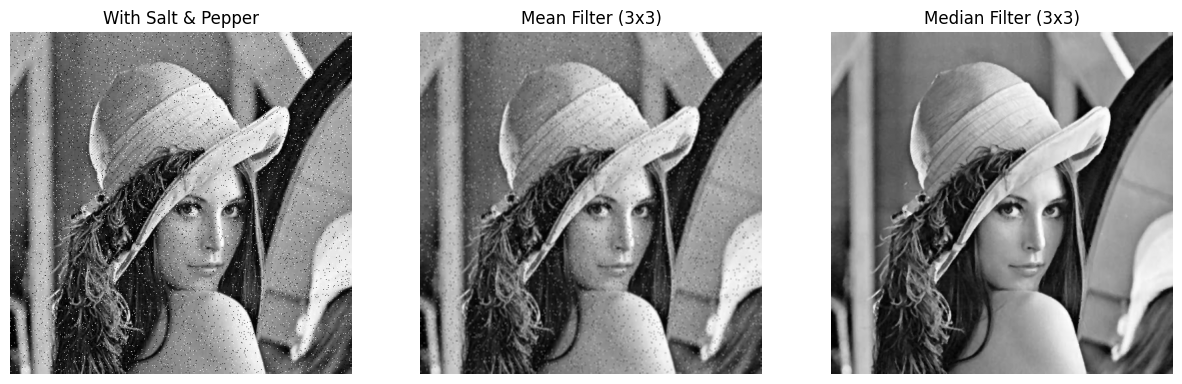

In [30]:
# Terapkan Mean Filter (blur biasa) ukuran 3x3 dan Median Filter ukuran 3x3
mean_filtered = cv.blur(img_noisy, (3, 3))
median_filtered = cv.medianBlur(img_noisy, 3)

show_side_by_side(
    [img_noisy, mean_filtered, median_filtered],
    ["With Salt & Pepper", "Mean Filter (3x3)", "Median Filter (3x3)"]
)

Karena Median Filter bekerja dengan mengambil nilai tengah dari piksel tetangga, sehingga bintik ekstrem (seperti putih pekat atau hitam pekat dari noise) langsung dibuang. Sebaliknya, Mean Filter merata-rata seluruh piksel di dalam kernel, yang justru membuat bintik noise tersebut menyebar dan membuat gambar keseluruhan jadi buram/kusam.

###2. Tugas Evaluasi: Pemilihan Ukuran Kernel untuk Menajamkan Citra (Sharpening)

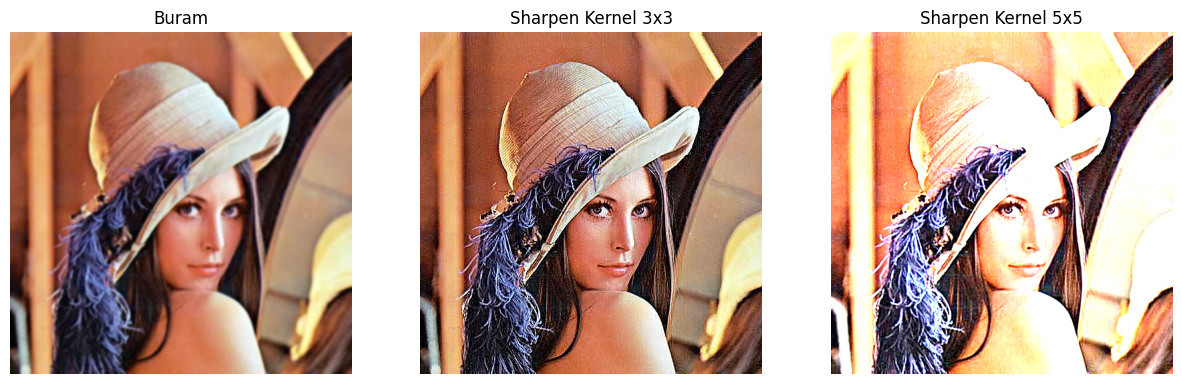

In [34]:
img_blurry = cv.GaussianBlur(img, (5, 5), 1.5)

kernel_3x3 = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]])

kernel_5x5 = np.array([[-1, -1, -1, -1, -1],
                       [-1,  2,  2,  2, -1],
                       [-1,  2, 16,  2, -1],
                       [-1,  2,  2,  2, -1],
                       [-1, -1, -1, -1, -1]]) / 8.0

sharp_3x3 = cv.filter2D(img, -1, kernel_3x3)
sharp_5x5 = cv.filter2D(img, -1, kernel_5x5)

show_side_by_side(
    [img_blurry, sharp_3x3, sharp_5x5],
    ["Buram", "Sharpen Kernel 3x3", "Sharpen Kernel 5x5"]
)

Kernel 3x3 biasanya paling optimal untuk penggunaan sehari-hari karena menajamkan tepi dengan pas tanpa membuat gambar terlihat terlalu berbintik (grainy). Sementara itu, kernel 5 x 5 terlalu kuat, sehingga memunculkan noise distortion yang bikin gambar keliatan pecah atau terlalu tajam yang tidak natural.

###Tugas Kreasi: Filter Kartun Sederhana

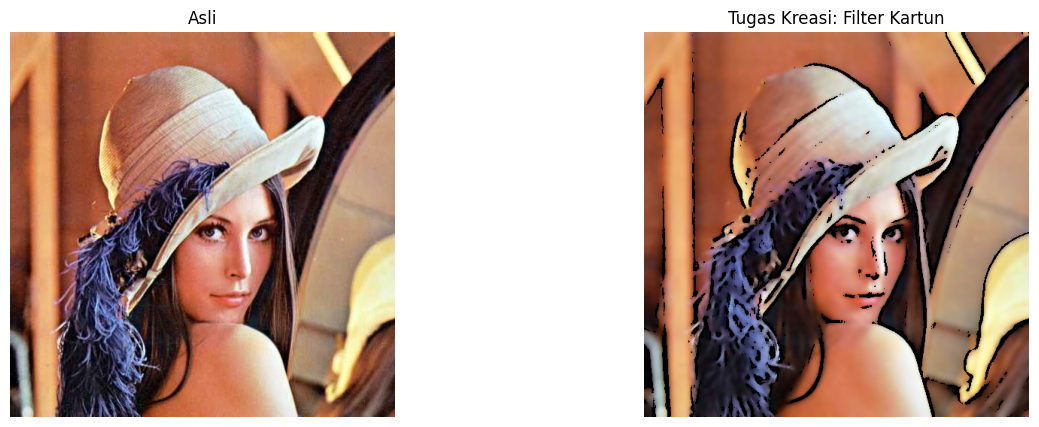

In [37]:
# a. Buat fungsi kustom kartun(image)
def kartun(image):
    # Step 1: Penghalusan warna menggunakan Bilateral Filter
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    # Step 2: Deteksi garis tepi menggunakan Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                  cv.ADAPTIVE_THRESH_MEAN_C,
                                  cv.THRESH_BINARY, 9, 9)

    # Step 3: Penggabungan menggunakan operasi logika (bitwise_and dengan mask edges)
    cartoon_result = cv.bitwise_and(color, color, mask=edges)
    return cartoon_result

img_cartoon = kartun(img)

# b. Tampilkan hasil citra asli dengan citra efek kartun bersebelahan[cite: 18]
show_side_by_side(
    [img, img_cartoon],
    ["Asli", "Tugas Kreasi: Filter Kartun"]
)